# Agentic Statistical Analysis Assistant: Multi-Agent LangGraph

**Module 6 assignment: Visualize Your Multi-Agent LangGraph**
Project team: Jingcheng Zhou, Lyu Junliang

This notebook implements the core workflow of our project as a real LangGraph `StateGraph`, runs it, and renders the diagram **from the same compiled graph object** that runs the examples.

**Case (from our case-study design):** a CSV of 80 students with `student_id`, `tutoring` (yes/no) and `score` (0-100).
Question: *Do students who attended tutoring have a different average exam score from those who did not?*
Participation was voluntary, so a difference in means is an association, not a causal effect.
Target parameter: Δ = μ(tutoring = yes) − μ(tutoring = no). H0: Δ = 0, H1: Δ ≠ 0, α = 0.05. Candidate method: two-sided Welch independent-samples t-test.

**Two agents, two different models**
* **Analysis Agent = Model A.** It plans, judges whether the data and design fit the plan, writes clarification questions, and writes and revises the explanation.
* **Review Agent = Model B, a different underlying LLM.** It checks Model A's explanation against the raw R results, the research design and the data-processing record.

R scripts, the numeric checker and the save step are **tools or program steps, not agents**.

**Data:** the CSV files in `data/` are **synthetic** (generated by `r/make_synthetic_data.R`). All statistics shown below are computed by R from these files at run time. Nothing is copied from the PDF.

## 0. Setup

**Requirements**
* Python 3.11+ with the packages in `requirements.txt` (versions used: see the output of the next cell)
* R 4.x with the `jsonlite` package
* For real model runs, either
  * **local models via [Ollama](https://ollama.com)** (free, no API key; e.g. `ollama:qwen3:8b` and `ollama:gemma3:12b`), or
  * **cloud APIs** with `OPENAI_API_KEY` (Model A) and `ANTHROPIC_API_KEY` (Model B).

  Models and keys are set in a `.env` file (see `.env.example`).

**How Python and R are connected.** LangGraph (Python) runs the workflow. When a node needs statistics, Python:
1. writes a small *request* JSON file (data file, data version, excluded IDs, settings),
2. runs `Rscript r/stats_tools.R <task> request.json result.json` as a subprocess,
3. reads the *result* JSON that R wrote back into the graph state.

R does the data checks and the t-test; Python never recomputes them. RStudio is only where we develop and test the R script; the workflow calls `Rscript` directly.

In [1]:
import csv
import glob
import json
import operator
import os
import re
import shutil
import subprocess
import threading
import time
import uuid
from pathlib import Path
from typing import Annotated, Literal, TypedDict

import pandas as pd
from pydantic import BaseModel, Field
from langchain_core.messages import HumanMessage, SystemMessage
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.config import get_config
from langgraph.graph import END, START, StateGraph
from langgraph.types import Command, interrupt

import importlib.metadata as _md
for _pkg in ["langgraph", "langgraph-checkpoint", "langchain", "langchain-core",
             "langchain-openai", "langchain-anthropic", "langchain-ollama", "pydantic", "pandas"]:
    try:
        print(f"{_pkg:22s} {_md.version(_pkg)}")
    except _md.PackageNotFoundError:
        print(f"{_pkg:22s} not installed")

langgraph              1.2.14
langgraph-checkpoint   4.2.0
langchain              1.4.4
langchain-core         1.6.9
langchain-openai       1.7.0
langchain-anthropic    1.7.5
langchain-ollama       1.1.0
pydantic               2.14.0
pandas                 3.0.6


In [2]:
# ---- Project paths and analysis settings ----------------------------------
PROJECT_DIR = Path.cwd()
R_SCRIPT = PROJECT_DIR / "r" / "stats_tools.R"
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
assert R_SCRIPT.exists(), "Run this notebook from the project folder (the folder that contains r/ and data/)."

ALPHA = 0.05                      # significance level fixed in the analysis plan
SCORE_MIN, SCORE_MAX = 0, 100     # score range stated by the user
GROUP_LABELS = ["yes", "no"]      # group 1 = tutoring, group 2 = no tutoring; Δ = mean(yes) - mean(no)
MAX_REPORT_REVISIONS = 1          # Model A may revise its explanation at most once
MAX_CLARIFICATION_ROUNDS = 2      # our choice for this stage; the case study does not fix a number
RUN_CONFIG = {"recursion_limit": 50}   # a broken loop fails fast instead of running on

## 1. Configure Model A and Model B separately

Each model is set by its own variable (`MODEL_A`, `MODEL_B`, format `provider:model`) and created by its own `init_chat_model` call. The code refuses to run if both settings resolve to the same provider and model.

A model can be a cloud API model (`openai:...`, `anthropic:...`) or a local model served by Ollama (`ollama:...`). Local models need no key, but the Ollama app must be running and the models must be downloaded with `ollama pull`.

**`LLM_MODE`:** `real` calls the two LLMs. `mock` swaps both agents for rule-based stand-ins, so the graph's control flow can be tested without any model. `auto` (the default) picks `real` when every chosen model is usable: an API key is set for each cloud model; local Ollama models need none.
Mock stand-ins are **not language models**. A mock run shows that state passing and routing work. It does **not** show how real models collaborate.

In [3]:
try:                                   # optional: read API keys and model names from .env
    from dotenv import load_dotenv
    load_dotenv(PROJECT_DIR / ".env")
except ImportError:
    pass

MODEL_A_NAME = os.getenv("MODEL_A", "openai:gpt-4.1-mini")         # Analysis Agent
MODEL_B_NAME = os.getenv("MODEL_B", "anthropic:claude-sonnet-5-5")  # Review Agent (different vendor)
LLM_MODE = os.getenv("LLM_MODE", "auto").lower()

PROVIDERS = ("openai", "anthropic", "google_genai", "ollama")
_KEY_FOR_PROVIDER = {"openai": "OPENAI_API_KEY", "anthropic": "ANTHROPIC_API_KEY",
                     "google_genai": "GOOGLE_API_KEY"}

def resolved_model(model_name: str) -> tuple:
    """(provider, model) as init_chat_model resolves it,
    e.g. 'gpt-4.1-mini' -> ('openai', 'gpt-4.1-mini'), 'ollama:qwen3:8b' -> ('ollama', 'qwen3:8b')."""
    name = model_name.strip().lower()
    prefix, _, rest = name.partition(":")
    if prefix in PROVIDERS and rest:
        return prefix, rest
    provider = ("openai" if name.startswith(("gpt-", "o1", "o3", "o4", "chatgpt")) else
                "anthropic" if name.startswith("claude") else
                "google_genai" if name.startswith("gemini") else "")
    return provider, name

def _key_present(model_name: str) -> bool:
    env_var = _KEY_FOR_PROVIDER.get(resolved_model(model_name)[0])
    return env_var is None or bool(os.getenv(env_var))   # local ollama models need no key

def check_ollama_models(model_names: list) -> None:
    """For local models: is the Ollama app running, and have the models been downloaded?"""
    import requests
    wanted = [resolved_model(n)[1] for n in model_names if resolved_model(n)[0] == "ollama"]
    if not wanted:
        return
    try:
        tags = requests.get("http://localhost:11434/api/tags", timeout=5).json()
    except requests.RequestException:
        raise RuntimeError("Ollama is not running: start the Ollama app, then re-run this cell.")
    have = {m["name"] for m in tags.get("models", [])}
    missing = [m for m in wanted if (m if ":" in m else m + ":latest") not in have]
    if missing:
        raise RuntimeError(f"Download the local model(s) first, e.g.  ollama pull {missing[0]}")

def make_chat_model(model_name: str):
    """Create one chat model. Cloud APIs and local Ollama models take different settings."""
    from langchain.chat_models import init_chat_model
    if resolved_model(model_name)[0] == "ollama":
        # Local model: a larger context window than Ollama's default and deterministic sampling.
        # "Thinking" is off by default because it made one call take ~100 s; set OLLAMA_THINKING=on to enable.
        thinking = os.getenv("OLLAMA_THINKING", "off").lower() == "on"
        return init_chat_model(model_name, num_ctx=16384, num_predict=8192, temperature=0, reasoning=thinking)
    # Cloud model: no temperature argument, because several current models only accept their default value.
    return init_chat_model(model_name, max_tokens=16000, timeout=180, max_retries=2)

if LLM_MODE == "auto":
    LLM_MODE = "real" if (_key_present(MODEL_A_NAME) and _key_present(MODEL_B_NAME)) else "mock"
assert LLM_MODE in ("real", "mock"), "LLM_MODE must be 'real', 'mock' or 'auto'"

if LLM_MODE == "real":
    if resolved_model(MODEL_A_NAME) == resolved_model(MODEL_B_NAME):
        raise ValueError("Model A and Model B must be different underlying models.")
    check_ollama_models([MODEL_A_NAME, MODEL_B_NAME])
    llm_model_a = make_chat_model(MODEL_A_NAME)
    llm_model_b = make_chat_model(MODEL_B_NAME)

print(f"LLM_MODE = {LLM_MODE.upper()}")
if LLM_MODE == "real":
    print(f"  Model A (Analysis Agent): {MODEL_A_NAME}")
    print(f"  Model B (Review Agent):   {MODEL_B_NAME}")
else:
    print("  MOCK MODE: both agents are rule-based stand-ins (no LLM calls).")
    print("  Use this only to test the graph's control flow; it does not test model behaviour.")

LLM_MODE = REAL
  Model A (Analysis Agent): ollama:qwen3:8b
  Model B (Review Agent):   ollama:gemma3:12b


## 2. The R tool bridge (Python → Rscript → JSON)

In [4]:
def find_rscript() -> str:
    """Locate Rscript: env var RSCRIPT_PATH, then PATH, then the default Windows install folder."""
    if os.getenv("RSCRIPT_PATH"):
        return os.getenv("RSCRIPT_PATH")
    on_path = shutil.which("Rscript")
    if on_path:
        return on_path
    candidates = sorted(glob.glob(r"C:\Program Files\R\R-*\bin\Rscript.exe"))
    if candidates:
        return candidates[-1]
    raise FileNotFoundError("Rscript not found. Install R or set the RSCRIPT_PATH environment variable.")

RSCRIPT = find_rscript()

def run_r_tool(task: str, request: dict, tag: str) -> dict:
    """Run one R task. Python writes request JSON -> Rscript computes -> Python reads result JSON."""
    io_dir = OUTPUT_DIR / "r_io"
    io_dir.mkdir(parents=True, exist_ok=True)
    request_path = io_dir / f"{tag}_{task}_request.json"
    result_path = io_dir / f"{tag}_{task}_result.json"
    request_path.write_text(json.dumps(request, indent=2), encoding="utf-8")
    proc = subprocess.run([RSCRIPT, str(R_SCRIPT), task, str(request_path), str(result_path)],
                          capture_output=True, text=True, encoding="utf-8", errors="replace", timeout=180)
    if proc.returncode != 0:
        raise RuntimeError(f"R task '{task}' failed:\n{proc.stderr}")
    return json.loads(result_path.read_text(encoding="utf-8"))

def r_request(state: dict) -> dict:
    """The same request (same data version, same exclusions) is sent to every R task."""
    return {"data_path": str(Path(state["data_path"]).resolve()),
            "data_version": state["data_version"],
            "excluded_ids": state.get("excluded_ids", []),
            "score_min": SCORE_MIN, "score_max": SCORE_MAX,
            "group_labels": GROUP_LABELS, "alpha": ALPHA}

print("Rscript:", RSCRIPT)

Rscript: C:\Program Files\R\R-4.4.1\bin\Rscript.exe


## 3. State

One shared state dictionary flows through the graph. Each node returns **only the keys it changes**.
The two parallel diagnostic branches write to **different keys** (`llm_diagnostic_report`, `r_diagnostic_report`), so they never overwrite each other.
Keys marked `Annotated[list, operator.add]` are logs: new entries are appended, never replaced.

In [5]:
class AnalysisState(TypedDict, total=False):
    # --- user input ----------------------------------------------------------
    run_id: str
    research_question: str
    design_info: dict                 # study-design facts stated by the user (not inferred from the CSV)
    original_data_path: str           # never modified
    # --- data version used by every node ----------------------------------------
    data_version: str                 # "v1" = original file; v2, v3 ... after user-confirmed changes
    data_path: str                    # CSV of the current data version
    excluded_ids: list                # records left out of the analysis set (each one user-confirmed)
    verified_ids: list                # unusual values the user verified as genuine (kept)
    # --- Model A's plan ---------------------------------------------------------
    analysis_plan: dict
    # --- diagnostics: shared input + one key per parallel branch ------------------
    data_summary: dict                # R summary read by the LLM branch (the R branch re-reads the same data version)
    llm_diagnostic_report: dict       # written only by node llm_diagnostics (Model A)
    r_diagnostic_report: dict         # written only by node r_diagnostics (R tool)
    diagnostic_decision: dict         # route = proceed / needs_clarification / stop, plus reasons
    # --- human in the loop ------------------------------------------------------
    clarification_requests: list
    user_confirmations: Annotated[list, operator.add]   # every round of user answers
    clarification_rounds: int
    user_requested_stop: bool
    correction_log: Annotated[list, operator.add]       # every change / exclusion / verification
    # --- analysis and report ----------------------------------------------------
    r_results: dict                   # raw R output of the Welch test
    stats_block: dict                 # protected, program-formatted statistics
    report_draft: dict                # Model A's current explanation
    numeric_check: dict               # program comparison of the draft with r_results
    review: dict                      # latest combined review decision
    review_history: Annotated[list, operator.add]
    revision_count: int
    # --- outcome ---------------------------------------------------------------
    final_status: str                 # delivered / stopped_at_diagnostics / stopped_after_review
    final_report: str
    session_record_path: str
    # --- testing and tracing -----------------------------------------------------
    test_fault: dict                  # TEST INPUT only: deliberately inject an error into a draft
    trace: Annotated[list, operator.add]

def trace_entry(node: str, t_start: float, **details) -> list:
    """One record per node run: superstep number, thread and timing (shows the real parallel branches)."""
    try:
        step = get_config().get("metadata", {}).get("langgraph_step")
    except RuntimeError:                 # called outside a graph run (e.g. a unit test)
        step = None
    return [{"node": node, "step": step, "thread": threading.current_thread().name,
             "start": t_start, "end": time.time(), **details}]

## 4. Structured outputs exchanged between the agents

Both models return Pydantic objects. The program can therefore route on fields such as `passed` instead of parsing free text.

In [6]:
class AnalysisPlan(BaseModel):
    target_parameter: str = Field(description="Population quantity to estimate, e.g. Δ = μ(yes) − μ(no)")
    group_1_label: str = Field(description="CSV label of group 1 (tutoring)")
    group_2_label: str = Field(description="CSV label of group 2 (no tutoring)")
    null_hypothesis: str
    alternative_hypothesis: str
    candidate_method: str
    method_rationale: str
    design_notes: list[str] = Field(description="Design facts that limit interpretation")
    status: str = Field(description="Always 'pending data and design review' at this stage")

class DiagnosticIssue(BaseModel):
    topic: Literal["variable_meaning", "study_design", "goal_alignment", "distribution", "other"]
    severity: Literal["note", "limitation", "out_of_scope"] = Field(
        description="out_of_scope ONLY if the planned test cannot validly answer the question "
                    "(e.g. paired data, non-numeric outcome, not two groups); voluntary participation is a limitation")
    issue: str
    evidence: str
    suggested_action: str

class LLMDiagnosticReport(BaseModel):
    variable_meanings: str
    design_assessment: str
    goal_alignment: str
    distribution_notes: str
    issues: list[DiagnosticIssue]

class ClarificationQuestion(BaseModel):
    request_id: str
    question: str

class MergeAssessment(BaseModel):
    rationale: str = Field(description="Why the analysis proceeds, pauses for clarification, or stops")
    limitations: list[str] = Field(description="Limitations to carry into the report")
    questions: list[ClarificationQuestion] = Field(description="One question per open request_id (empty if none)")

class LimitationText(BaseModel):
    limitation_id: str = Field(description="One of the required_limitations ids")
    text: str

class ReportedStatistics(BaseModel):
    """The statistics the report states, copied as text from the protected block (checked field by field)."""
    mean_difference: str
    ci_lower: str
    ci_upper: str
    t_statistic: str
    df: str
    p_value: str
    n_included: str

class ReportDraft(BaseModel):
    interpretation: str = Field(description="3-6 plain sentences; numbers copied exactly from the protected block")
    reported_statistics: ReportedStatistics
    limitations: list[LimitationText]
    direction_claim: Literal["tutoring_group_higher", "tutoring_group_lower", "equal_sample_means"]
    decision_claim: Literal["reject_H0", "do_not_reject_H0"]

class ReviewIssue(BaseModel):
    severity: Literal["critical", "minor"]
    category: Literal["causal_claim", "numeric_mismatch", "contradiction", "missing_result",
                      "missing_limitation", "unsupported_claim", "overstatement", "other"]
    offending_sentence: str
    evidence: str
    suggested_correction: str

class ReviewVerdict(BaseModel):
    passed: bool = Field(description="True only if there is no critical issue")
    issues: list[ReviewIssue]
    summary: str

## 5. The two agents

`AnalysisAgentA` is **one agent** (Model A) that is used by several nodes: planning, diagnostics, merging, drafting and revising.
`ReviewAgentB` is a separate agent backed by a **different model** (Model B).

In [7]:
SYSTEM_PROMPT_A = """You are the Analysis Agent (Model A) of a statistical analysis assistant.
You plan analyses, judge whether data and design fit the plan, write clarification questions,
and explain results that were computed by R.
Rules:
- Statistical numbers come only from the R results you are given. Copy them exactly as written in the
  protected statistics block. Never recompute them, round them differently, or invent numbers.
- Never delete, edit or impute data yourself. Any data change needs a user confirmation.
- When groups were not randomized (e.g. voluntary participation), describe associations only. Never claim causation.
- A Shapiro-Wilk p-value never decides the method by itself. Welch's t-test does not assume equal variances.
- Do not switch to a method that answers a different question (e.g. a rank test about distributions
  instead of the mean difference)."""

PLAN_TASK = """Create the structured analysis plan for the user's request.
Example (different study): "Is mean reaction time different between caffeine and placebo groups? 60 adults
were randomly assigned." -> target Δ = μ(caffeine) − μ(placebo); H0: Δ = 0; H1: Δ ≠ 0;
candidate method: two-sided Welch independent-samples t-test; design note: randomized.
Rules:
- Choose candidate_method only from supported_methods (the statistical tools available in this stage).
  If none of them answers the question, write "no supported method" and explain why in method_rationale.
- The significance level is a fixed project setting (given as alpha in the input); the program adds it to the plan.
- Do not plan a switch to another method based on a normality test.
- Use the CSV labels given in group_labels for group_1_label and group_2_label (in that order)."""

SUPPORTED_METHODS = ["two-sided Welch independent-samples t-test (difference in two population means)"]

DIAGNOSE_TASK = """Review the shared R summary of the current data version, the plan and the user's design facts.
Assess: variable meanings, study design, alignment between the question and the planned test, and
what the distribution summary suggests (skew, extreme values, odd labels).
For each issue give evidence and a suggested action. You do NOT see the rule-based R diagnostics; they
are merged later, so do not decide record-level corrections."""

MERGE_TASK = """The program has combined your diagnostic report with the R diagnostics and set the route
(proceed / needs_clarification / stop) using fixed rules. Explain the route in plain language, list the
limitations that must be carried into the report, and write one short, specific question for every open
request (quote the record id, the value as written and the allowed responses). Do not change the route."""

DRAFT_TASK = """Write the explanation for the user from the protected statistics block.
- Copy every number exactly as written in the block (same rounding, same sign). Do not introduce any number
  that is not in the block, apart from alpha (write "α = 0.05"), the confidence level (write "95% CI")
  and the 0-100 score range.
- Fill reported_statistics by copying the block's values as text.
- Write the interpretation as ONE plain paragraph (no numbering, no bullet points) with these sentences, in this order:
  1. how many students were analysed in each group;
  2. the hypotheses and Welch's test result: t(df) = t_statistic, p = p_value;
  3. the decision at α = 0.05: "we reject H0" or "we do not reject H0" (for "do not reject", add that this
     is not evidence that the two means are equal);
  4. the estimated mean difference (tutoring minus no tutoring) with its 95% CI, and which group's sample
     mean was higher;
  5. that this is an association only, because participation was voluntary.
- Write exactly one limitation entry for each id in required_limitations (the block gives the required
  content) and no other entries. Do not add claims that the evidence does not support (e.g. that a check
  was not done, or that another method should be used because of a normality test)."""

REVISE_TASK = """Revise your previous draft using the reviewer's feedback and the program's numeric check.
- sentences_to_fix lists the exact sentences the reviewer objected to. Each of them must NOT appear in your
  revised interpretation: delete it, or replace it with the reviewer's suggested_correction if that
  correction follows the rules.
- Fix every numeric_check_problem.
- Keep the other, correct sentences unchanged. The same rules as for the first draft apply."""

SYSTEM_PROMPT_B = """You are the Review Agent (Model B). You did not write the report you are reviewing.
Check the explanation against the original evidence: the raw R results, the protected statistics block,
the research design, the analysis plan and the data-processing record (corrections, exclusions, verified values).
Rubric. An issue is CRITICAL only if it is one of these:
1. causal_claim: the text says or implies that tutoring caused, improved, increased, raised or led to higher
   scores, or calls the difference an "effect" of tutoring. Groups were not randomized.
   NOT causal (acceptable): "associated with", "a statistically significant difference / association",
   "students who attended tutoring scored higher on average", and any sentence that says the result does
   NOT establish causation.
2. numeric_mismatch: a number in the text differs from the protected statistics block. Quote both values.
   A number that equals the block value is correct (the program_numeric_check has already compared them).
3. contradiction: the stated decision or direction disagrees with the R results (e.g. "do not reject H0"
   although p < alpha), or two sentences contradict each other.
4. missing_limitation: an id in required_limitations is absent or stated incorrectly.
5. overstatement: e.g. "proves", "definitely", or treating a non-significant result as proof of no difference.
   Writing "we reject H0 at alpha = 0.05" when p < alpha is correct, not an overstatement.
6. missing_result: the interpretation does not state the test result (t, df, p), the decision about H0,
   or the estimated difference with its confidence interval.
7. unsupported_claim: a statement the evidence contradicts or does not support, e.g. that a check was not
   done when the R results show it, or a recommendation to switch to another method because of a normality
   test (Welch's test was planned; Shapiro-Wilk results are descriptive only).
Use 'minor' only for optional wording improvements. Do not list a sentence that is correct.
For each issue quote the offending sentence, give the evidence and propose a correction.
Set passed=true if and only if there is no critical issue."""


def _as_json(payload: dict) -> str:
    return json.dumps(payload, indent=2, ensure_ascii=False, default=str)


class AnalysisAgentA:
    """Analysis Agent backed by Model A (a real LLM)."""
    def __init__(self, llm, model_name: str):
        self.llm, self.model_name = llm, model_name

    def _ask(self, schema, task: str, payload: dict):
        structured = self.llm.with_structured_output(schema, method="json_schema")
        return structured.invoke([SystemMessage(SYSTEM_PROMPT_A),
                                  HumanMessage(f"{task}\n\nINPUT (JSON):\n{_as_json(payload)}")])

    def plan(self, question, design_info, columns):
        return self._ask(AnalysisPlan, PLAN_TASK, {"research_question": question, "design_info": design_info,
                         "csv_columns": columns, "group_labels": GROUP_LABELS, "alpha": ALPHA,
                         "supported_methods": SUPPORTED_METHODS})

    def diagnose(self, plan, design_info, data_summary):
        return self._ask(LLMDiagnosticReport, DIAGNOSE_TASK,
                         {"analysis_plan": plan, "design_info": design_info, "shared_r_summary": data_summary})

    def merge(self, **evidence):
        return self._ask(MergeAssessment, MERGE_TASK, evidence)

    def draft(self, context):
        return self._ask(ReportDraft, DRAFT_TASK, context)

    def revise(self, context, previous_draft, review_feedback, numeric_problems):
        to_fix = [i["offending_sentence"] for i in review_feedback if i["severity"] == "critical"]
        return self._ask(ReportDraft, REVISE_TASK, {**context, "previous_draft": previous_draft,
                         "sentences_to_fix": to_fix,
                         "review_feedback_from_model_b": review_feedback,
                         "numeric_check_problems": numeric_problems})


class ReviewAgentB:
    """Review Agent backed by Model B (a different real LLM)."""
    def __init__(self, llm, model_name: str):
        self.llm, self.model_name = llm, model_name

    def review(self, evidence: dict) -> ReviewVerdict:
        structured = self.llm.with_structured_output(ReviewVerdict, method="json_schema")
        return structured.invoke([SystemMessage(SYSTEM_PROMPT_B),
                                  HumanMessage(f"Review this report.\n\nEVIDENCE (JSON):\n{_as_json(evidence)}")])

### Mock stand-ins (used only when `LLM_MODE = "mock"`)

The stand-ins return the same Pydantic objects from fixed templates and simple rules. They let us check that every branch of the graph is reachable and that state flows correctly. They are **not** evidence of model quality.

In [8]:
def default_question(item: dict) -> str:
    return (f"Record {item['record_id']}: {item['field']} = \"{item['value_as_written']}\" ({item['detail']}). "
            f"Allowed responses: {', '.join(item['allowed_responses'])}.")


class MockAnalysisAgentA:
    """RULE-BASED STAND-IN for Model A (mock mode only). Not an LLM."""
    model_name = "MOCK stand-in for Model A (rule-based, no LLM)"

    def plan(self, question, design_info, columns):
        return AnalysisPlan(
            target_parameter="Δ = μ(tutoring = yes) − μ(tutoring = no)",
            group_1_label=GROUP_LABELS[0], group_2_label=GROUP_LABELS[1],
            null_hypothesis="H0: Δ = 0", alternative_hypothesis="H1: Δ ≠ 0",
            candidate_method="Two-sided Welch independent-samples t-test",
            method_rationale="The question asks about a difference in mean scores between two independent groups.",
            design_notes=[design_info.get("assignment", ""), design_info.get("independence", "")],
            status="pending data and design review")

    def diagnose(self, plan, design_info, data_summary):
        issues = []
        if data_summary.get("status") != "ok":
            issues.append(DiagnosticIssue(topic="variable_meaning", severity="note",
                          issue="The file does not contain all variables named in the request.",
                          evidence=f"columns found: {data_summary.get('columns_found')}",
                          suggested_action="Ask the user for the correct file."))
            return LLMDiagnosticReport(variable_meanings="Required variables are missing.", design_assessment="",
                                       goal_alignment="", distribution_notes="", issues=issues)
        if "not random" in design_info.get("assignment", "").lower():
            issues.append(DiagnosticIssue(topic="study_design", severity="limitation",
                          issue="Groups are self-selected, not randomized.",
                          evidence=design_info["assignment"],
                          suggested_action="Report an association only; no causal wording."))
        labels = [x["label_as_written"] for x in data_summary["tutoring_label_counts"]]
        if set(labels) - set(GROUP_LABELS):
            issues.append(DiagnosticIssue(topic="variable_meaning", severity="note",
                          issue="Some tutoring labels differ from yes/no as written.",
                          evidence=f"labels as written: {[x['quoted'] for x in data_summary['tutoring_label_counts']]}",
                          suggested_action="Confirm the intended group with the user."))
        q = data_summary.get("score_quantiles") or {}
        if q and (q["max"] > SCORE_MAX or q["min"] < SCORE_MIN):
            issues.append(DiagnosticIssue(topic="distribution", severity="note",
                          issue="Scores outside the stated 0-100 range are present.",
                          evidence=f"min = {q['min']}, max = {q['max']}",
                          suggested_action="Verify the affected records before testing."))
        return LLMDiagnosticReport(
            variable_meanings="student_id identifies a student; tutoring is the self-reported group; score is the exam score (0-100).",
            design_assessment=f"{design_info.get('assignment')}; {design_info.get('independence')}",
            goal_alignment="The question concerns a mean difference between two independent groups, which the Welch test targets.",
            distribution_notes=f"Score quantiles: {q}",
            issues=issues)

    def merge(self, route, open_items, stop_reasons, **_):
        rationale = {"proceed": "No unresolved record-level problems remain; the planned Welch test can run.",
                     "needs_clarification": f"{len(open_items)} record(s) need the user's verification before testing.",
                     "stop": "The analysis cannot continue: " + " ".join(stop_reasons)}[route]
        return MergeAssessment(rationale=rationale, limitations=[],
                               questions=[ClarificationQuestion(request_id=i["request_id"], question=default_question(i))
                                          for i in open_items])

    def draft(self, context):
        sb = context["stats_block"]
        g1, g2 = sb["groups"]
        reject = sb["decision"] == "reject_H0"
        p_text = f"p {sb['p_value']}" if sb["p_value"].startswith("<") else f"p = {sb['p_value']}"
        only_missing = "excluded_missing_scores" in sb["required_limitations"] and \
            "excluded_flagged_records" not in sb["required_limitations"]
        kind = "complete-case analysis" if only_missing else "analysis"
        text = (f"The {kind} included {sb['n_included']} students "
                f"({g1['n']} with tutoring, {g2['n']} without). For H0: Δ = 0 versus H1: Δ ≠ 0, Welch's test gave "
                f"t({sb['df']}) = {sb['t_statistic']}, {p_text}. At α = {sb['alpha']}, we "
                f"{'reject' if reject else 'do not reject'} H0 under the analysis assumptions. "
                f"The estimated mean difference (tutoring minus no tutoring) was {sb['mean_difference']} points "
                f"({sb['confidence_level']} CI: {sb['ci_lower']} to {sb['ci_upper']}).")
        if not reject:
            text += " This does not show that the two population means are equal."
        limitations = [LimitationText(limitation_id=lid, text=lim_text)
                       for lid, lim_text in sb["required_limitations"].items()]
        direction = {1: "tutoring_group_higher", -1: "tutoring_group_lower", 0: "equal_sample_means"}[sb["direction_sign"]]
        reported = ReportedStatistics(**{f: sb[f] for f in ReportedStatistics.model_fields})
        return ReportDraft(interpretation=text, reported_statistics=reported, limitations=limitations,
                           direction_claim=direction, decision_claim="reject_H0" if reject else "do_not_reject_H0")

    def revise(self, context, previous_draft, review_feedback, numeric_problems):
        # The stand-in simply regenerates its template draft (which follows every rule);
        # unlike a real model it does not read the feedback.
        return self.draft(context)


class MockReviewAgentB:
    """RULE-BASED STAND-IN for Model B (mock mode only). Not an LLM: keyword rules only."""
    model_name = "MOCK stand-in for Model B (rule-based, no LLM)"
    CAUSAL = re.compile(r"\b(caus\w*|led to|because of tutoring|effect of tutoring|"
                        r"tutoring (improv|increas|rais|boost)\w*)\b", re.I)
    # A causal word is accepted only when a negation governs it, e.g. "does not establish that tutoring caused".
    NEGATED_CAUSAL = re.compile(r"\b(not|cannot|n't)\b[^.]{0,60}?\b(caus|establish|show|impl)", re.I)

    def review(self, evidence):
        draft = evidence["report_draft"]
        issues = []
        for sentence in re.split(r"(?<=[.!?])\s+", draft["interpretation"]):
            if self.CAUSAL.search(sentence) and not self.NEGATED_CAUSAL.search(sentence):
                issues.append(ReviewIssue(severity="critical", category="causal_claim", offending_sentence=sentence,
                              evidence="design_info: participation was voluntary (not randomized)",
                              suggested_correction="Describe an association; remove causal wording."))
        covered = {l["limitation_id"] for l in draft["limitations"]}
        for lid, required_text in evidence["stats_block"]["required_limitations"].items():
            if lid not in covered:
                issues.append(ReviewIssue(severity="critical", category="missing_limitation", offending_sentence="(missing)",
                              evidence=f"required limitation '{lid}'", suggested_correction=required_text))
        return ReviewVerdict(passed=not issues, issues=issues,
                             summary="Rule-based mock review: " + ("no issues found." if not issues else f"{len(issues)} issue(s)."))


if LLM_MODE == "real":
    AGENT_A = AnalysisAgentA(llm_model_a, MODEL_A_NAME)
    AGENT_B = ReviewAgentB(llm_model_b, MODEL_B_NAME)
else:
    AGENT_A = MockAnalysisAgentA()
    AGENT_B = MockReviewAgentB()
print("Analysis Agent:", AGENT_A.model_name)
print("Review Agent:  ", AGENT_B.model_name)

Analysis Agent: ollama:qwen3:8b
Review Agent:   ollama:gemma3:12b


## 6. Node functions

### 6.1 Planning and parallel diagnostics

In [9]:
def plan_analysis(state: AnalysisState) -> dict:
    """Analysis Agent (Model A): question + design + column names -> structured analysis plan."""
    t0 = time.time()
    columns = list(pd.read_csv(state["original_data_path"], nrows=0).columns)
    plan = AGENT_A.plan(state["research_question"], state["design_info"], columns).model_dump()
    # The significance level is a fixed project setting, so the program (not the model) records it.
    plan |= {"alpha": ALPHA, "confidence_level": 1 - ALPHA, "alpha_source": "fixed project setting"}
    return {"analysis_plan": plan, "trace": trace_entry("plan_analysis", t0)}


def prepare_data_summary(state: AnalysisState) -> dict:
    """R tool: shared descriptive summary of the CURRENT data version (no pass/fail verdicts)."""
    t0 = time.time()
    summary = run_r_tool("summary", r_request(state), tag=f"{state['run_id']}_{state['data_version']}")
    return {"data_summary": summary,
            "trace": trace_entry("prepare_data_summary", t0, data_version=state["data_version"])}


def llm_diagnostics(state: AnalysisState) -> dict:
    """PARALLEL BRANCH 1 - Analysis Agent (Model A): variable meaning, design, goal alignment, distribution.
    It sees only the shared summary; the R verdicts are withheld until the merge."""
    t0 = time.time()
    report = AGENT_A.diagnose(state["analysis_plan"], state["design_info"], state["data_summary"])
    return {"llm_diagnostic_report": {**report.model_dump(), "data_version": state["data_version"]},
            "trace": trace_entry("llm_diagnostics", t0, data_version=state["data_version"])}


def r_diagnostics(state: AnalysisState) -> dict:
    """PARALLEL BRANCH 2 - R tool: missingness, types, ranges, labels, duplicate IDs,
    group sizes, variation, boxplot flags (and Shapiro-Wilk only after invalid values are fixed)."""
    t0 = time.time()
    report = run_r_tool("diagnostics", r_request(state), tag=f"{state['run_id']}_{state['data_version']}")
    return {"r_diagnostic_report": report,
            "trace": trace_entry("r_diagnostics", t0, data_version=state["data_version"])}

### 6.2 Merge the two diagnostic reports and decide: proceed, clarify or stop

The **route is decided by explicit rules on the state**. Model A explains the decision and words the questions, but it cannot change the route.

In [10]:
RESPONSE_OPTIONS = {          # what the user may answer for each type of R finding
    "missing_score":     ["exclude", "<number>", "stop"],
    "non_numeric_score": ["<number>", "exclude", "stop"],
    "non_finite_score":  ["<number>", "exclude", "stop"],
    "out_of_range":      ["<number>", "exclude", "stop"],
    "invalid_label":     ["yes", "no", "exclude", "stop"],
    "missing_label":     ["yes", "no", "exclude", "stop"],
    "duplicate_id":      ["exclude", "stop"],
    "missing_id":        ["stop"],
    "boxplot_flag":      ["keep", "<number>", "exclude", "stop"],
}


def plan_scope_problems(plan: dict) -> list:
    """Program check: is the plan inside what this stage supports (two-sided Welch on yes vs no)?"""
    problems = []
    if "welch" not in plan["candidate_method"].lower():
        problems.append(f"Planned method '{plan['candidate_method']}' is outside the supported scope (Welch t-test).")
    if [plan["group_1_label"], plan["group_2_label"]] != GROUP_LABELS:
        problems.append("Plan group labels do not match the data labels yes/no.")
    return problems


def merge_diagnostics(state: AnalysisState) -> dict:
    """Analysis Agent (Model A) + program rules: combine both reports -> proceed / needs_clarification / stop."""
    t0 = time.time()
    r_rep, l_rep, version = state["r_diagnostic_report"], state["llm_diagnostic_report"], state["data_version"]
    if not (r_rep["data_version"] == l_rep["data_version"] == version):
        raise RuntimeError("The two diagnostic branches described different data versions.")

    # Reasons that stop the analysis (it cannot answer the question with this data/design).
    stop_reasons = []
    if r_rep["status"] == "missing_required_columns":
        stop_reasons.append(f"Required column(s) missing: {', '.join(r_rep['missing_required_columns'])}.")
    stop_reasons += [g["detail"] for g in r_rep.get("group_findings", [])]
    stop_reasons += [f"Model A design check: {i['issue']}" for i in l_rep["issues"] if i["severity"] == "out_of_scope"]
    stop_reasons += plan_scope_problems(state["analysis_plan"])
    if state.get("user_requested_stop"):
        stop_reasons.append("The user chose 'stop' during clarification.")

    # Record-level problems that need the user: all blocking ones + boxplot flags not yet verified.
    # (R reports group size / variation only after these are resolved, so fixable label or score
    # problems are always asked about first instead of stopping the run.)
    findings = r_rep.get("findings", [])
    duplicated_ids = {f["record_id"] for f in findings if f["check"] == "duplicate_id"}
    verified, open_items, seen = set(state.get("verified_ids", [])), [], set()
    for f in findings:
        request_id = f"{f['record_id']}:{f['check']}"
        if request_id in seen or (f["severity"] == "verify" and f["record_id"] in verified):
            continue
        seen.add(request_id)
        options = RESPONSE_OPTIONS[f["check"]]
        if f["record_id"] in duplicated_ids:      # an edit could not tell the rows apart: exclude or stop only
            options = ["exclude", "stop"]
        open_items.append({"request_id": request_id, **f, "allowed_responses": options})

    rounds = state.get("clarification_rounds", 0)
    if stop_reasons:
        route = "stop"
    elif open_items and rounds >= MAX_CLARIFICATION_ROUNDS:
        route = "stop"
        stop_reasons.append(f"{len(open_items)} record(s) still unresolved after {rounds} clarification round(s).")
    elif open_items:
        route = "needs_clarification"
    else:
        route = "proceed"

    assessment = AGENT_A.merge(route=route, open_items=open_items, stop_reasons=stop_reasons,
                               llm_report=l_rep, r_report=r_rep, design_info=state["design_info"],
                               correction_log=state.get("correction_log", []))
    worded = {q.request_id: q.question for q in assessment.questions}
    requests = [{**i, "question": worded.get(i["request_id"]) or default_question(i)} for i in open_items] \
        if route == "needs_clarification" else []
    decision = {"route": route, "data_version": version, "stop_reasons": stop_reasons,
                "n_open_items": len(open_items), "rationale": assessment.rationale,
                "limitations": assessment.limitations + [i["issue"] for i in l_rep["issues"] if i["severity"] == "limitation"],
                "distribution_checks": r_rep.get("distribution_checks")}
    return {"diagnostic_decision": decision, "clarification_requests": requests,
            "trace": trace_entry("merge_diagnostics", t0, route=route)}

### 6.3 Human-in-the-loop clarification and user-confirmed corrections

`request_clarification` calls `interrupt()`. The graph **pauses**, the state is saved by the checkpointer, and the notebook shows the questions. The run continues only when the notebook sends the user's typed answers back with `Command(resume=answers)`. The program never invents an answer.

In [11]:
def parse_user_answer(request: dict, answer: dict) -> dict:
    """Program validation of one typed answer (no LLM). Raises ValueError if it is not allowed."""
    text = str(answer.get("response", "")).strip()
    reason = str(answer.get("reason", "")).strip()
    options, low = request["allowed_responses"], text.lower()
    base = {"request_id": request["request_id"], "record_id": request["record_id"], "field": request["field"],
            "check": request["check"], "value_as_written": request["value_as_written"],
            "reason": reason, "response": text}
    if low == "stop" and "stop" in options:
        return {**base, "action": "stop", "value": None}
    if low == "exclude" and "exclude" in options:
        action, value = "exclude", None
    elif low == "keep" and "keep" in options:
        action, value = "keep", None
    elif low in GROUP_LABELS and low in options:
        action, value = "set_label", low
    elif "<number>" in options and re.fullmatch(r"[0-9]+(\.[0-9]+)?", text):    # plain digits only, e.g. 85 or 85.5
        if not SCORE_MIN <= float(text) <= SCORE_MAX:
            raise ValueError(f"'{text}' must be a number between {SCORE_MIN} and {SCORE_MAX}")
        action, value = "set_score", f"{float(text):g}"
    else:
        raise ValueError(f"'{text}' is not one of the allowed responses {options}")
    if not reason:
        raise ValueError("a reason / source is required for every change, exclusion or verification")
    return {**base, "action": action, "value": value}


def request_clarification(state: AnalysisState) -> dict:
    """HUMAN-IN-THE-LOOP: pause the graph and wait for the user's answers (interrupt / resume)."""
    requests = state["clarification_requests"]
    previous = state.get("user_confirmations") or []
    payload = {"data_version": state["data_version"], "requests": requests,
               "previous_rejections": previous[-1]["rejected"] if previous else []}
    answers = interrupt(payload)            # <- graph pauses here until Command(resume=answers)
    t0 = time.time()                        # (the node restarts on resume; nothing above has side effects)
    accepted, rejected = [], []
    for req in requests:
        answer = (answers or {}).get(req["request_id"], {})
        try:
            accepted.append(parse_user_answer(req, answer))
        except ValueError as err:
            rejected.append({"request_id": req["request_id"], "answer": answer, "problem": str(err)})
    rnd = state.get("clarification_rounds", 0) + 1
    record = {"round": rnd, "data_version": state["data_version"], "source": "answers typed by the user in the notebook",
              "accepted": accepted, "rejected": rejected}
    return {"user_confirmations": [record], "clarification_rounds": rnd,
            "trace": trace_entry("request_clarification", t0, accepted=len(accepted), rejected=len(rejected))}


def apply_corrections(state: AnalysisState) -> dict:
    """Program step: apply ONLY user-confirmed changes, save them as a NEW data version and log each one.
    The original CSV is never modified. Nothing is dropped or imputed automatically."""
    t0 = time.time()
    latest = state["user_confirmations"][-1]
    old_version = state["data_version"]
    new_version = f"v{int(old_version[1:]) + 1}"
    df = pd.read_csv(state["data_path"], dtype=str, keep_default_na=False)   # keep every value exactly as text
    excluded, verified = set(state.get("excluded_ids", [])), set(state.get("verified_ids", []))
    log, stop = [], False
    for item in latest["accepted"]:
        rows = df["student_id"] == item["record_id"]
        new_value = None
        if item["action"] == "set_score":
            df.loc[rows, "score"] = item["value"]; new_value = item["value"]
        elif item["action"] == "set_label":
            df.loc[rows, "tutoring"] = item["value"]; new_value = item["value"]
        elif item["action"] == "exclude":
            excluded.add(item["record_id"]); new_value = "(excluded from the analysis set; row kept in file)"
        elif item["action"] == "keep":
            verified.add(item["record_id"]); new_value = "(verified by user; retained unchanged)"
        elif item["action"] == "stop":
            stop = True
        log.append({"round": latest["round"], "record_id": item["record_id"], "field": item["field"],
                    "check": item["check"], "action": item["action"], "rows_affected": int(rows.sum()),
                    "old_value": item["value_as_written"], "new_value": new_value,
                    "reason": item["reason"], "source": "user confirmation",
                    "from_version": old_version, "to_version": new_version})
    version_dir = OUTPUT_DIR / "data_versions"
    version_dir.mkdir(parents=True, exist_ok=True)
    new_path = version_dir / f"{state['run_id']}_{new_version}.csv"
    df.to_csv(new_path, index=False)
    return {"data_version": new_version, "data_path": str(new_path),
            "excluded_ids": sorted(excluded), "verified_ids": sorted(verified),
            "correction_log": log, "user_requested_stop": stop,
            "trace": trace_entry("apply_corrections", t0, new_version=new_version, changes=len(log))}

### 6.4 R analysis, protected statistics block, Model A's draft and the numeric check

In [12]:
def run_r_analysis(state: AnalysisState) -> dict:
    """R tool: two-sided Welch t-test on the current data version and analysis set."""
    t0 = time.time()
    results = run_r_tool("welch_test", r_request(state), tag=f"{state['run_id']}_{state['data_version']}")
    if results["status"] != "ok":      # R refuses to run if record-level problems remain (double safety)
        raise RuntimeError(f"R did not run the test: {results.get('reason')}")
    return {"r_results": results, "trace": trace_entry("run_r_analysis", t0, data_version=state["data_version"])}


def format_p(p: float) -> str:
    """4 decimals, but never let rounding print a value on the wrong side of alpha (e.g. 0.04996 -> 0.049960)."""
    if p < 0.0001:
        return "< 0.0001"
    text = f"{p:.4f}"
    return f"{p:.6f}" if text == f"{ALPHA:.4f}" and p != ALPHA else text


def required_limitations(state: AnalysisState) -> dict:
    """Limitations the report must state, built from the design and the correction log: {id: required content}."""
    required = {"non_random_assignment": "Participation was voluntary rather than randomized, so this comparison "
                                         "does not establish that tutoring caused any difference in scores."}
    excluded = [e for e in state.get("correction_log", []) if e["action"] == "exclude"]
    missing = sorted({e["record_id"] for e in excluded if e["check"] == "missing_score"})
    other = sorted({f"{e['record_id']} ({e['check'].replace('_', ' ')})" for e in excluded if e["check"] != "missing_score"})
    if missing:
        required["excluded_missing_scores"] = (
            f"Records with a missing score were excluded after user confirmation ({', '.join(missing)}), so this is "
            "a complete-case analysis; unknown reasons for missingness may bias the comparison and limit "
            "generalization to all students.")
    if other:
        required["excluded_flagged_records"] = (
            f"Records were excluded by user decision for reasons other than missing data ({', '.join(other)}); "
            "excluding flagged values is an analyst choice that can change the estimate.")
    if state.get("verified_ids"):
        required["verified_unusual_values_retained"] = (
            f"Scores flagged by the boxplot rule were verified by the user and retained "
            f"({', '.join(state['verified_ids'])}).")
    return required


def build_stats_block(state: AnalysisState) -> dict:
    """Program step: format the protected statistics from the stored R result (fixed rounding)."""
    t0 = time.time()
    r = state["r_results"]
    p = r["p_value"]
    diff = r["mean_difference"]
    block = {
        "data_version": state["data_version"],
        "method": "Welch two-sample t-test, two-sided, var.equal = FALSE",
        "hypotheses": "H0: Δ = 0 versus H1: Δ ≠ 0, where Δ = μ(tutoring = yes) − μ(tutoring = no)",
        "alpha": f"{ALPHA:g}", "confidence_level": f"{100 * (1 - ALPHA):g}%",
        "groups": [{"group": f"tutoring = {g['label']}", "n": str(g["n"]),
                    "mean": f"{g['mean']:.2f}", "sd": f"{g['sd']:.2f}"} for g in (r["group_1"], r["group_2"])],
        "n_included": str(r["n_included"]), "n_excluded": str(len(state.get("excluded_ids", []))),
        "excluded_ids": state.get("excluded_ids", []), "verified_ids": state.get("verified_ids", []),
        "mean_difference": f"{diff:.2f}", "ci_lower": f"{r['ci_lower']:.2f}", "ci_upper": f"{r['ci_upper']:.2f}",
        "t_statistic": f"{r['t_statistic']:.3f}", "df": f"{r['df']:.2f}",
        "p_value": format_p(p),
        "decision": "reject_H0" if p < ALPHA else "do_not_reject_H0",
        "direction_sign": (diff > 0) - (diff < 0),
        "shapiro_wilk_p": {d["group"]: f"{d['shapiro_wilk_p']:.3f}"            # descriptive diagnostics only
                           for d in (state["diagnostic_decision"].get("distribution_checks") or [])
                           if d.get("shapiro_wilk_p") is not None},
        "required_limitations": required_limitations(state),
    }
    return {"stats_block": block, "trace": trace_entry("build_stats_block", t0)}


def report_context(state: AnalysisState) -> dict:
    """Everything Model A needs to write (or revise) the explanation."""
    return {"research_question": state["research_question"], "design_info": state["design_info"],
            "analysis_plan": state["analysis_plan"], "stats_block": state["stats_block"],
            "diagnostic_limitations": state["diagnostic_decision"]["limitations"],
            "correction_log": state.get("correction_log", [])}


def maybe_inject_test_fault(draft: dict, state: AnalysisState) -> dict:
    """TEST INPUT ONLY. If state['test_fault'] is set, add a deliberately wrong sentence to the draft,
    so the review / revision branches can be tested. Recorded in the draft as test_fault_injected."""
    fault = state.get("test_fault")
    if not fault or (fault["apply_to"] == "first_draft" and draft["version"] > 1):
        return draft
    sb = state["stats_block"]
    if fault["type"] == "causal_claim":
        sentence = f"Tutoring caused scores to increase by {sb['mean_difference']} points."
    else:   # "wrong_number"
        sentence = f"The estimated mean difference was {float(sb['mean_difference']) + 1.5:.2f} points."
    return {**draft, "interpretation": draft["interpretation"] + " " + sentence,
            "test_fault_injected": f"TEST INPUT ({fault['type']}): {sentence}"}


def draft_report(state: AnalysisState) -> dict:
    """Analysis Agent (Model A): write the explanation from the protected statistics block."""
    t0 = time.time()
    draft = AGENT_A.draft(report_context(state)).model_dump() | {"version": 1}
    draft = maybe_inject_test_fault(draft, state)
    return {"report_draft": draft, "trace": trace_entry("draft_report", t0, version=1)}


NUMBER_PATTERN = re.compile(r"(?<![\w.])[-−]?(?:\d+(?:\.\d+)?|\.\d+)")   # 12, 3.49, -0.51, .014


def check_report_numbers(state: AnalysisState) -> dict:
    """Program check against the stored R result (no LLM, no re-run of the test):
    1. each field of reported_statistics must equal the protected value exactly (sign and rounding);
    2. every number in the text must be a protected value or an allowed design constant. A number written
       with a minus sign must have the right sign; an unsigned magnitude ("0.94 points lower") is accepted;
    3. required content: the interpretation states the estimate, its CI, t and p, and decision wording
       that matches R ("reject H0" vs "do not reject H0");
    4. the declared direction and decision must match R;
    5. the limitations are exactly the required ones (none missing, none added).
    Whether the words around a number state the right direction is judged by Model B, not by this check."""
    t0 = time.time()
    sb, draft = state["stats_block"], state["report_draft"]
    problems = []
    # 1. Field-by-field comparison of the structured statistics
    for field, reported in draft["reported_statistics"].items():
        if str(reported).replace("−", "-").strip() != sb[field]:
            problems.append({"check": "field_mismatch",
                             "detail": f"{field}: report says '{reported}', stored R value is '{sb[field]}'"})
    # 2. Every number in the prose must be a protected value or a design constant
    protected = {f: sb[f] for f in ReportedStatistics.model_fields} | {"n_excluded": sb["n_excluded"]}
    protected["p_value"] = protected["p_value"].replace("<", "").strip()
    protected |= {f"{g['group']} {k}": g[k] for g in sb["groups"] for k in ("n", "mean", "sd")}
    protected |= {f"Shapiro-Wilk p ({grp})": v for grp, v in sb["shapiro_wilk_p"].items()}
    design_constants = {f"{ALPHA:g}", f"{1 - ALPHA:g}", f"{100 * (1 - ALPHA):g}",   # 0.05, 0.95, 95 (%)
                        str(SCORE_MIN), str(SCORE_MAX)}                            # the 0-100 score scale
    allowed = set(protected.values()) | {v.lstrip("-") for v in protected.values()} | design_constants
    # List markers such as "1. " or "2) " at the start of a line or sentence are not statistics.
    interpretation = re.sub(r"(^|[.!?]\s+)\(?\d{1,2}[.)]\s+", r"\1", draft["interpretation"], flags=re.M)
    text = interpretation + " " + " ".join(l["text"] for l in draft["limitations"])
    for raw in NUMBER_PATTERN.findall(text):
        num = raw.replace("−", "-")
        num = num.replace(".", "0.", 1) if num.lstrip("-").startswith(".") else num
        if num in allowed:
            continue
        same_digits = [(f, v) for f, v in protected.items() if v == num.lstrip("-")]
        if num.startswith("-") and same_digits:            # explicit minus sign on a positive value
            (field, value), kind = same_digits[0], "sign"
        else:
            field, value = min(protected.items(), key=lambda kv: abs(float(kv[1]) - float(num)))
            kind = "rounding" if abs(float(value) - float(num)) < 0.05 else "unverified_number"
        problems.append({"check": kind, "detail": f"'{num}' in the text does not match a stored R value "
                                                  f"(nearest: {field} = {value})"})
    # 3. Required content in the interpretation
    stated = {n.replace("−", "-").lstrip("-") for n in NUMBER_PATTERN.findall(interpretation)}
    for field in ("mean_difference", "ci_lower", "ci_upper", "t_statistic", "p_value"):
        if protected[field].lstrip("-") not in stated:
            problems.append({"check": "missing_content",
                             "detail": f"the interpretation does not state {field} = {sb[field]}"})
    says_not_reject = re.search(r"\b(not|n't|fail(s|ed)? to)\s+reject", interpretation, re.I)
    says_reject = re.search(r"\breject", interpretation, re.I)
    if sb["decision"] == "reject_H0" and (not says_reject or says_not_reject):
        problems.append({"check": "decision_wording", "detail": "R rejects H0; the text must say that H0 is rejected"})
    if sb["decision"] == "do_not_reject_H0" and not says_not_reject:
        problems.append({"check": "decision_wording", "detail": "R does not reject H0; the text must say so"})
    # 4. Structured direction and decision
    expected_direction = {1: "tutoring_group_higher", -1: "tutoring_group_lower", 0: "equal_sample_means"}[sb["direction_sign"]]
    if draft["direction_claim"] != expected_direction:
        problems.append({"check": "direction", "detail": f"claims {draft['direction_claim']}, R gives {expected_direction}"})
    if draft["decision_claim"] != sb["decision"]:
        problems.append({"check": "decision", "detail": f"claims {draft['decision_claim']}, R gives {sb['decision']}"})
    # 5. Limitations: exactly the required ones (extra entries could carry unsupported claims)
    written = {l["limitation_id"] for l in draft["limitations"]}
    missing, extra = set(sb["required_limitations"]) - written, written - set(sb["required_limitations"])
    if missing:
        problems.append({"check": "required_sections", "detail": f"missing limitation(s): {sorted(missing)}"})
    if extra:
        problems.append({"check": "required_sections",
                         "detail": f"limitation(s) not in required_limitations: {sorted(extra)}; remove them"})
    result = {"report_version": draft["version"], "passed": not problems, "problems": problems}
    return {"numeric_check": result, "trace": trace_entry("check_report_numbers", t0, passed=not problems)}

### 6.5 Model B review, Model A revision, delivery, stop and save

In [13]:
def review_report(state: AnalysisState) -> dict:
    """Review Agent (Model B). HANDOFF A -> B: Model A's draft plus the original evidence go to Model B."""
    t0 = time.time()
    draft = {k: v for k, v in state["report_draft"].items() if k != "test_fault_injected"}  # B is not told about tests
    evidence = {"report_draft": draft,
                "r_results_raw": state["r_results"],
                "stats_block": state["stats_block"],
                "research_question": state["research_question"],
                "design_info": state["design_info"],
                "analysis_plan": state["analysis_plan"],
                "data_processing_record": {"correction_log": state.get("correction_log", []),
                                           "excluded_ids": state.get("excluded_ids", []),
                                           "verified_ids": state.get("verified_ids", [])},
                "program_numeric_check": state["numeric_check"]}
    verdict = AGENT_B.review(evidence)
    # Model B fails a report only through a critical issue that names the sentence and the evidence
    # (its own passed flag is kept for the record, but a failure must be backed by a critical issue).
    critical = [i for i in verdict.issues if i.severity == "critical"]
    model_b_passed = not critical
    passed = model_b_passed and state["numeric_check"]["passed"]
    review = {"report_version": state["report_draft"]["version"], "reviewer": AGENT_B.model_name,
              "model_b_passed": model_b_passed, "model_b_flag": verdict.passed,
              "numeric_check_passed": state["numeric_check"]["passed"],
              "passed": passed, "issues": [i.model_dump() for i in verdict.issues], "summary": verdict.summary}
    return {"review": review, "review_history": [review],
            "trace": trace_entry("review_report", t0, passed=passed)}


def revise_report(state: AnalysisState) -> dict:
    """Analysis Agent (Model A). HANDOFF B -> A: Model B's issues + numeric problems come back to Model A."""
    t0 = time.time()
    previous = {k: v for k, v in state["report_draft"].items() if k not in ("version", "test_fault_injected")}
    revised = AGENT_A.revise(report_context(state), previous,
                             review_feedback=state["review"]["issues"],
                             numeric_problems=state["numeric_check"]["problems"])
    version = state["report_draft"]["version"] + 1
    draft = maybe_inject_test_fault(revised.model_dump() | {"version": version}, state)
    return {"report_draft": draft, "revision_count": state.get("revision_count", 0) + 1,
            "trace": trace_entry("revise_report", t0, version=version)}


def format_stats_block(sb: dict) -> str:
    rows = "\n".join(f"| {g['group']} | {g['n']} | {g['mean']} | {g['sd']} |" for g in sb["groups"])
    return (f"Method: {sb['method']}  (data version {sb['data_version']})\n{sb['hypotheses']}; α = {sb['alpha']}\n\n"
            f"| Group | n | Mean | SD |\n|---|---|---|---|\n{rows}\n\n"
            f"Mean difference = {sb['mean_difference']} ({sb['confidence_level']} CI {sb['ci_lower']} to {sb['ci_upper']}); "
            f"t({sb['df']}) = {sb['t_statistic']}; p = {sb['p_value']}; decision: {sb['decision']}\n"
            f"Shapiro-Wilk p by group (descriptive only, not used to choose the method): {sb['shapiro_wilk_p']}")


def deliver_report(state: AnalysisState) -> dict:
    """Program step: assemble the reviewed report (protected block + Model A's text + review status)."""
    t0 = time.time()
    d, rv = state["report_draft"], state["review"]
    lims = "\n".join(f"- {l['text']}" for l in d["limitations"])
    report = (f"REVIEWED REPORT (passed review of draft version {rv['report_version']}; reviewer: {rv['reviewer']})\n\n"
              f"{format_stats_block(state['stats_block'])}\n\nInterpretation (Model A):\n{d['interpretation']}\n\n"
              f"Limitations:\n{lims}")
    return {"final_status": "delivered", "final_report": report, "trace": trace_entry("deliver_report", t0)}


def issue_notice(state: AnalysisState) -> dict:
    """Program step: stop and explain why. After a failed review, show only R-verified descriptive results;
    the inferential narrative is withheld."""
    t0 = time.time()
    if state.get("review"):                                   # stopped after the review loop
        r = state["r_results"]
        desc = "\n".join(f"- tutoring = {g['label']}: n = {g['n']}, mean = {g['mean']:.2f}, SD = {g['sd']:.2f}"
                         for g in (r["group_1"], r["group_2"]))
        issues = "\n".join([f"- [model B, {i['severity']}] {i['category']}: {i['offending_sentence']}"
                            for i in state["review"]["issues"]] +
                           [f"- [numeric check] {p['check']}: {p['detail']}" for p in state["numeric_check"]["problems"]])
        status = "stopped_after_review"
        text = (f"ISSUE NOTICE: the explanation still had critical problems after {state.get('revision_count', 0)} "
                f"revision(s), so the inferential narrative is withheld.\n\nUnresolved issues:\n{issues}\n\n"
                f"Verified descriptive results from R (data version {state['data_version']}):\n{desc}")
    else:                                                     # stopped at the diagnostics stage
        status = "stopped_at_diagnostics"
        reasons = "\n".join(f"- {x}" for x in state["diagnostic_decision"]["stop_reasons"])
        text = (f"ISSUE NOTICE: the analysis was stopped before any test was run.\n\nReasons:\n{reasons}\n\n"
                f"Model A's explanation: {state['diagnostic_decision']['rationale']}")
    return {"final_status": status, "final_report": text, "trace": trace_entry("issue_notice", t0, status=status)}


def save_session(state: AnalysisState) -> dict:
    """Program step: save this run's short-term memory record (versions, decisions, results) as JSON."""
    t0 = time.time()
    keys = ["run_id", "research_question", "design_info", "original_data_path", "data_version", "data_path",
            "excluded_ids", "verified_ids", "analysis_plan", "diagnostic_decision", "user_confirmations",
            "correction_log", "r_results", "stats_block", "report_draft", "review_history",
            "revision_count", "final_status", "final_report", "test_fault"]
    record = {k: state.get(k) for k in keys} | {"llm_mode": LLM_MODE, "model_a": AGENT_A.model_name,
                                                "model_b": AGENT_B.model_name}
    session_dir = OUTPUT_DIR / "sessions"
    session_dir.mkdir(parents=True, exist_ok=True)
    path = session_dir / f"{state['run_id']}.json"
    path.write_text(json.dumps(record, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
    return {"session_record_path": str(path), "trace": trace_entry("save_session", t0)}

## 7. Conditional routing functions

Each router reads the current state and returns a label; `path_map` turns the label into the next node.
The labels appear on the dashed edges of the diagram.

In [14]:
def route_after_diagnostics(state: AnalysisState) -> str:
    """proceed -> run R test | needs_clarification -> ask the user | stop -> issue notice."""
    return state["diagnostic_decision"]["route"]


def route_after_review(state: AnalysisState) -> str:
    """Passed -> deliver | failed and not yet revised -> Model A revises once | failed after revision -> stop."""
    if state["review"]["passed"]:
        return "review_passed"
    if state.get("revision_count", 0) < MAX_REPORT_REVISIONS:
        return "revise_once"
    return "fail_after_revision"

## 8. Build and compile the graph

`metadata={"role": ...}` is printed inside each node of the auto-generated diagram, so the image itself shows which agent, tool or program step owns each node.

In [15]:
# Role labels are shown in the diagram; no parentheses, because they break Mermaid's node syntax.
MODEL_A_ROLE = "Analysis Agent - model A, LLM"
MODEL_B_ROLE = "Review Agent - model B, a different LLM"
NODE_ROLES = {
    "plan_analysis":         MODEL_A_ROLE,
    "prepare_data_summary":  "R tool via Rscript",
    "llm_diagnostics":       MODEL_A_ROLE + ", parallel branch",
    "r_diagnostics":         "R tool via Rscript, parallel branch",
    "merge_diagnostics":     MODEL_A_ROLE + " + routing rules",
    "request_clarification": "human-in-the-loop pause: interrupt",
    "apply_corrections":     "program step",
    "run_r_analysis":        "R tool via Rscript",
    "build_stats_block":     "program step",
    "draft_report":          MODEL_A_ROLE,
    "check_report_numbers":  "program check",
    "review_report":         MODEL_B_ROLE,
    "revise_report":         MODEL_A_ROLE,
    "deliver_report":        "program step",
    "issue_notice":          "program step",
    "save_session":          "program step",
}
NODE_FUNCTIONS = {
    "plan_analysis": plan_analysis, "prepare_data_summary": prepare_data_summary,
    "llm_diagnostics": llm_diagnostics, "r_diagnostics": r_diagnostics,
    "merge_diagnostics": merge_diagnostics, "request_clarification": request_clarification,
    "apply_corrections": apply_corrections, "run_r_analysis": run_r_analysis,
    "build_stats_block": build_stats_block, "draft_report": draft_report,
    "check_report_numbers": check_report_numbers, "review_report": review_report,
    "revise_report": revise_report, "deliver_report": deliver_report,
    "issue_notice": issue_notice, "save_session": save_session,
}

builder = StateGraph(AnalysisState)
for name, fn in NODE_FUNCTIONS.items():
    builder.add_node(name, fn, metadata={"role": NODE_ROLES[name]})

builder.add_edge(START, "plan_analysis")
builder.add_edge("plan_analysis", "prepare_data_summary")
# Fan-out: two edges leave the same node, so both branches run in the SAME superstep (in parallel).
builder.add_edge("prepare_data_summary", "llm_diagnostics")
builder.add_edge("prepare_data_summary", "r_diagnostics")
# Fan-in (join): merge_diagnostics runs only after BOTH branches have finished.
builder.add_edge(["llm_diagnostics", "r_diagnostics"], "merge_diagnostics")
builder.add_conditional_edges("merge_diagnostics", route_after_diagnostics,
                              {"needs_clarification": "request_clarification",
                               "proceed": "run_r_analysis",
                               "stop": "issue_notice"})
builder.add_edge("request_clarification", "apply_corrections")
builder.add_edge("apply_corrections", "prepare_data_summary")      # new data version -> fresh diagnostics
builder.add_edge("run_r_analysis", "build_stats_block")
builder.add_edge("build_stats_block", "draft_report")
builder.add_edge("draft_report", "check_report_numbers")
builder.add_edge("check_report_numbers", "review_report")
builder.add_conditional_edges("review_report", route_after_review,
                              {"review_passed": "deliver_report",
                               "revise_once": "revise_report",
                               "fail_after_revision": "issue_notice"})
builder.add_edge("revise_report", "check_report_numbers")          # revised draft is checked again
builder.add_edge("deliver_report", "save_session")
builder.add_edge("issue_notice", "save_session")
builder.add_edge("save_session", END)

graph = builder.compile(checkpointer=InMemorySaver())   # the checkpointer makes interrupt/resume possible
print("Compiled graph object id:", id(graph))
print("Nodes:", [n for n in graph.get_graph().nodes if not n.startswith("__")])

Compiled graph object id: 2465642719488
Nodes: ['plan_analysis', 'prepare_data_summary', 'llm_diagnostics', 'r_diagnostics', 'merge_diagnostics', 'request_clarification', 'apply_corrections', 'run_r_analysis', 'build_stats_block', 'draft_report', 'check_report_numbers', 'review_report', 'revise_report', 'deliver_report', 'issue_notice', 'save_session']


## 9. Visualize the compiled graph

The image below is generated from the compiled `graph` object above, using the code required by the assignment. The same object runs every example in Section 11.
`draw_mermaid_png()` sends the Mermaid text (node and edge names only, no data) to the mermaid.ink web service, so this cell needs internet access.

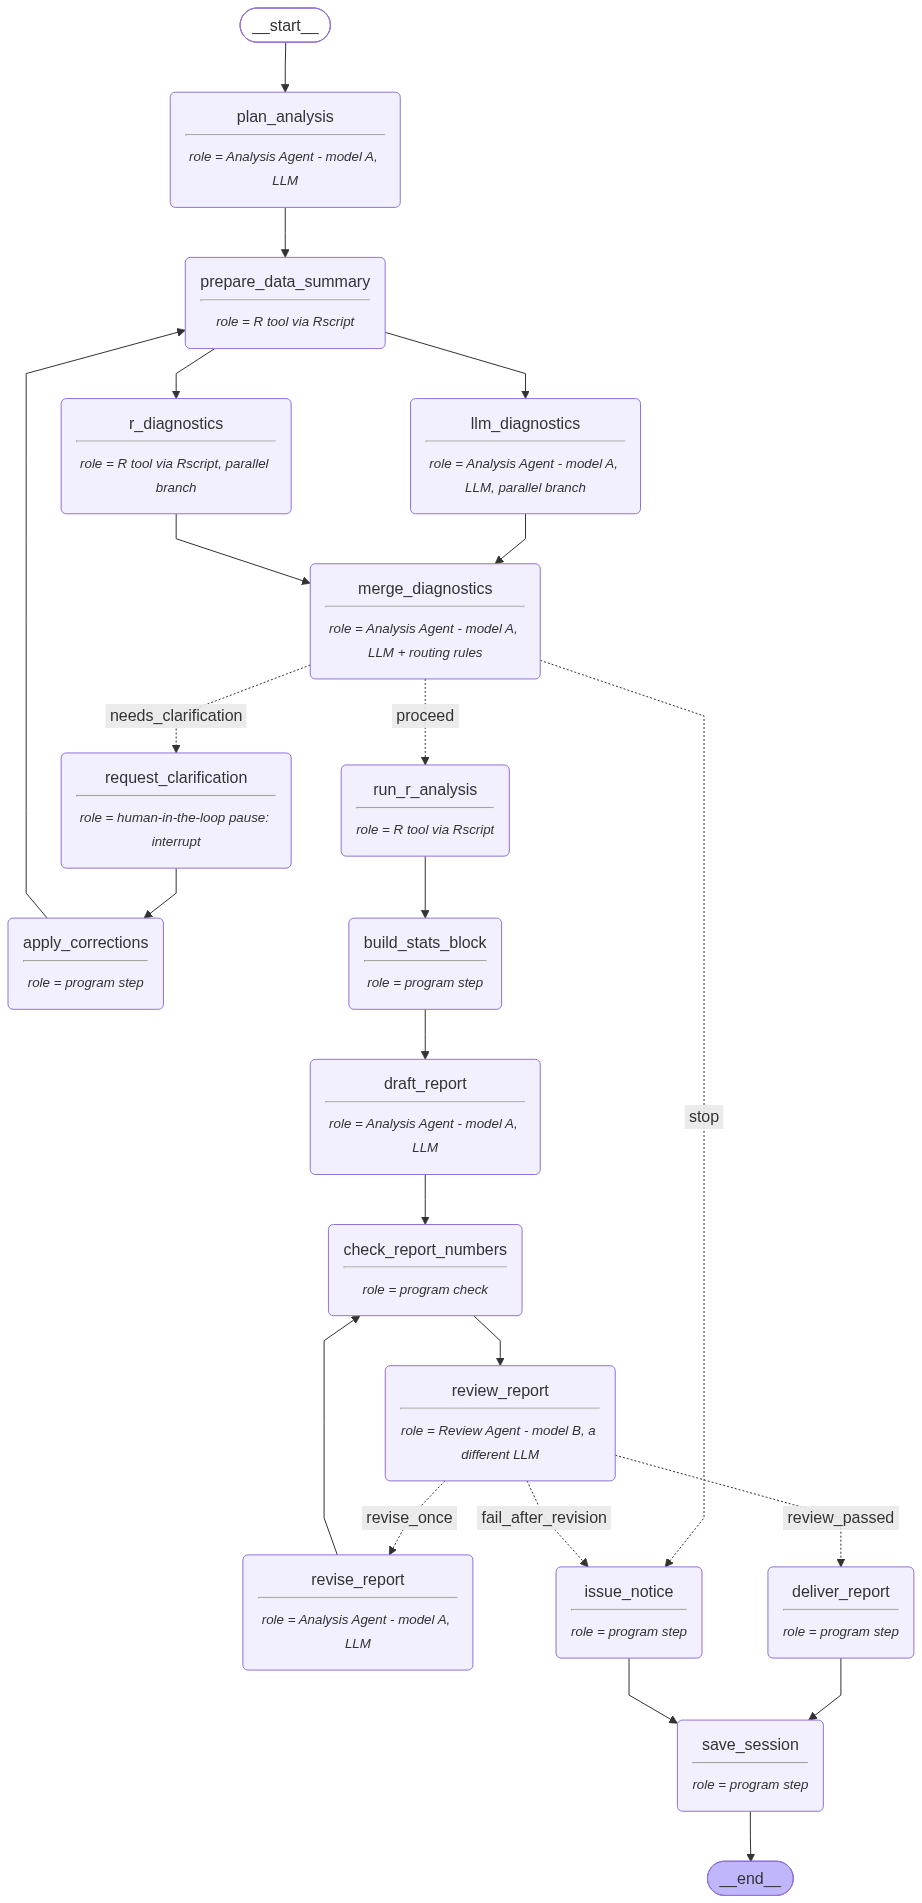

In [16]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [17]:
# Save the PNG of the same compiled graph object, plus the Mermaid source text for reference.
GRAPH_PNG = PROJECT_DIR / "stats_assistant_langgraph.png"
graph.get_graph().draw_mermaid_png(output_file_path=str(GRAPH_PNG))
(OUTPUT_DIR).mkdir(exist_ok=True)
(OUTPUT_DIR / "stats_assistant_langgraph.mmd").write_text(graph.get_graph().draw_mermaid(), encoding="utf-8")
GRAPH_ID_WHEN_DRAWN = id(graph)
print("Saved:", GRAPH_PNG.name, "| drawn from graph object id", GRAPH_ID_WHEN_DRAWN)

# Consistency check: the explanation table below covers exactly the nodes of the compiled graph.
drawn_nodes = {n for n in graph.get_graph().nodes if not n.startswith("__")}
assert drawn_nodes == set(NODE_ROLES), drawn_nodes ^ set(NODE_ROLES)
print("Every compiled node has a documented role:", len(drawn_nodes), "nodes")

Saved: stats_assistant_langgraph.png | drawn from graph object id 2465642719488
Every compiled node has a documented role: 16 nodes


## 10. What the diagram shows

The `role` captions in the image describe each node in the design. When the notebook runs with `LLM_MODE = MOCK` (the mode used when no API keys are present; Section 1 prints the mode actually used), the model A and model B nodes call rule-based stand-ins. The graph, the state passing and the routing are identical in real mode.

**Nodes** (the small text in each box is the node's `role` metadata from the code)

| Node | Agent / tool | What it does |
|---|---|---|
| `plan_analysis` | Analysis Agent, model A | Turns the question, the user's design facts, the CSV column names and the list of supported methods into a structured plan: Δ, H0/H1, two-sided Welch t-test. α = 0.05 is a fixed project setting that the program adds to the plan. |
| `prepare_data_summary` | R tool (Rscript) | Builds one descriptive summary of the current data version: label counts as written, quantiles, group statistics. The LLM branch reads this summary. The R branch re-reads the same data version (same file, same exclusions). |
| `llm_diagnostics` | Analysis Agent, model A (parallel branch) | Judges variable meaning, study design, question–method fit and the distribution summary. It cannot see the R verdicts. |
| `r_diagnostics` | R tool (parallel branch) | Rule-based checks: missingness, numeric/finite values, 0–100 range, labels, duplicate IDs, boxplot flags. Group size and variation are checked once no record-level problem is open. Shapiro–Wilk runs only after invalid values are fixed, and only as information. |
| `merge_diagnostics` | Analysis Agent, model A + routing rules | Checks that both reports describe the same data version and applies fixed rules to choose proceed / needs_clarification / stop. Model A explains the decision and words the record-specific questions. |
| `request_clarification` | Human-in-the-loop (`interrupt`) | Pauses the graph and shows the questions, plus any answers rejected in the previous round. The user's typed answers resume the run and are validated by code. |
| `apply_corrections` | Program step | Applies only user-confirmed changes and writes a new data version; the original file is untouched. Logs ID, check, action, rows affected, old/new value, reason and source. |
| `run_r_analysis` | R tool (Rscript) | `t.test(..., alternative = "two.sided", var.equal = FALSE, conf.level = 0.95)` on the current data version. |
| `build_stats_block` | Program step | Formats the protected statistics from the stored R result (fixed rounding). Builds the required limitations from the design and the correction log. |
| `draft_report` | Analysis Agent, model A | Writes the explanation from the protected block, plus the statistics it reports as structured fields. |
| `check_report_numbers` | Program check | Compares the draft with the stored R result without re-running the test. Each reported statistic field must match exactly, in value, sign and rounding. Every number in the text must be a protected value or α, 95%, 0 or 100; a number written with a minus sign must have the right sign. The interpretation must state the estimate, its CI, t and p, with decision wording that matches R ("reject" / "do not reject H0"). The declared direction and decision must match R, and every required limitation must be present. Whether the words around a number state the right direction is left to model B. |
| `review_report` | Review Agent, model B | Reviews the draft against the raw R results, design, plan and data-processing record. Returns pass/fail with issues. |
| `revise_report` | Analysis Agent, model A | Revises the draft once using model B's issues and the numeric problems. |
| `deliver_report` | Program step | Assembles the reviewed report. |
| `issue_notice` | Program step | Stops with reasons. After a failed review it shows only verified descriptive results and withholds the inferential narrative. |
| `save_session` | Program step | Saves the run record (data versions, confirmations, corrections, plan, results, reviews, status) to `outputs/sessions/`. |

**Solid edges** (whenever the source node runs, the target runs next):
* `__start__ → plan_analysis → prepare_data_summary`: the question and design go to model A; model A's structured plan is passed on to the data stage.
* `prepare_data_summary → llm_diagnostics` and `prepare_data_summary → r_diagnostics` form the **fan-out**. Both branches run in the same superstep on the same data version and write different state keys.
* `llm_diagnostics → merge_diagnostics` and `r_diagnostics → merge_diagnostics` look like two ordinary arrows in the picture, but in the code they are **one join**: `add_edge(["llm_diagnostics", "r_diagnostics"], "merge_diagnostics")`. The merge waits for **both** branches.
* `request_clarification → apply_corrections → prepare_data_summary` loops back once the user's answers resume the paused graph. Every user-confirmed change triggers fresh diagnostics on the new data version.
* `run_r_analysis → build_stats_block → draft_report → check_report_numbers → review_report`. The chain carries the raw R test output, then the protected statistics block, then model A's draft, then the program's numeric check, and finally model B's review.
* `revise_report → check_report_numbers → review_report`: a revised draft is checked by the program and model B again.
* `deliver_report` and `issue_notice` both go to `save_session`; `save_session → __end__` ends the run.

**Dashed (conditional) edges**: labels are the router outputs computed from the state. At `merge_diagnostics`, stop reasons take precedence; otherwise open record-level problems lead to clarification; otherwise the run proceeds.
* From `merge_diagnostics`:
  * `needs_clarification` → `request_clarification` when R found record-level problems (missing, non-numeric, non-finite or out-of-range score; missing or invalid label; duplicate ID) or unverified boxplot flags. The test is never run while data questions are open.
  * `proceed` → `run_r_analysis` when no open problem remains.
  * `stop` → `issue_notice` when the analysis cannot answer the question. That happens when a required column is missing, a group is too small or has no variation after record-level problems are resolved, model A judges the design out of scope, the plan is outside the supported scope, the user answered "stop", or problems remain after 2 clarification rounds.
* From `review_report`:
  * `review_passed` → `deliver_report` when model B lists no critical issue **and** the program's numeric check passed. Model B can only fail a report through a critical issue that quotes the sentence and gives the evidence; minor issues are suggestions.
  * `revise_once` → `revise_report` when the review failed and `revision_count` is 0.
  * `fail_after_revision` → `issue_notice` when the review failed after one revision, i.e. `revision_count` has reached 1.

**Where the multi-agent handoff happens**
* **A → B at `review_report`.** Model A's draft, from `draft_report` or `revise_report`, becomes model B's input together with the original evidence. The evidence is the raw R results (`r_results`), the protected statistics block, the research question and design, the analysis plan, the data-processing record (correction log, excluded and verified IDs) and the program's numeric check. Model B does not see whether a test fault was injected.
* **B → A at `revise_report`.** Model B's `review.issues` (offending sentence, evidence, suggested correction) and the numeric-check problems become model A's input for its single revision.
* Within model A's own work, the plan from `plan_analysis` is also read by `llm_diagnostics`, by the scope check in `merge_diagnostics` and by `draft_report` / `revise_report`. That is one agent passing state along, not a handoff between agents.

**Agent handoff vs. tool call.** A handoff passes one agent's output to another **agent's model** for judgement: A's report goes to B, and B's critique comes back to A. A tool call (`prepare_data_summary`, `r_diagnostics`, `run_r_analysis`) runs a fixed R script through `Rscript` and returns structured numbers. The R script makes no decision about the workflow. The program steps and the numeric check are ordinary code, not agents.

## 11. Run the examples with the same `graph` object

Helper functions: create the initial state, show the path taken, and collect the user's answers when the graph pauses.

In [18]:
RESEARCH_QUESTION = ("I uploaded a CSV of 80 students. Do students who attended tutoring have different average "
                     "exam scores from those who did not? Scores range from 0 to 100. Each row is a different "
                     "student; participation was voluntary, and observations can be treated as independent.")
DESIGN_INFO = {   # design facts come from the user's statement, not from the CSV
    "unit": "student; each row is a different student",
    "outcome": "score: exam score on a 0-100 scale",
    "group_variable": "tutoring: 'yes' = attended tutoring, 'no' = did not",
    "assignment": "voluntary participation (self-selected, not randomized)",
    "independence": "observations can be treated as independent (stated by the user)",
}


def new_run(name: str, data_file: Path, test_fault: dict | None = None):
    run_id = f"{name}-{uuid.uuid4().hex[:6]}"
    state = {"run_id": run_id, "research_question": RESEARCH_QUESTION, "design_info": DESIGN_INFO,
             "original_data_path": str(data_file), "data_path": str(data_file), "data_version": "v1",
             "excluded_ids": [], "verified_ids": [], "clarification_rounds": 0, "revision_count": 0,
             "user_requested_stop": False, "test_fault": test_fault}
    config = {"configurable": {"thread_id": run_id}, **RUN_CONFIG}
    return state, config


def show_path(result: dict) -> None:
    """Print the nodes in execution order; nodes in the same superstep are shown as parallel."""
    steps = {}
    for t in result.get("trace", []):
        steps.setdefault(t["step"], []).append(t)
    parts = []
    for _, entries in sorted(steps.items(), key=lambda kv: kv[0]):
        names = [e["node"] for e in entries]
        parts.append(names[0] if len(names) == 1 else "{" + " ∥ ".join(names) + "}")
    print(" → ".join(parts))


def show_parallel_evidence(result: dict) -> None:
    """For each diagnostics round: superstep, thread, data version and time window of both branches."""
    t_first = result["trace"][0]["start"]
    for t in result["trace"]:
        if t["node"] in ("llm_diagnostics", "r_diagnostics"):
            print(f"  step {t['step']:>2} | {t['node']:16s} | data {t['data_version']} | thread {t['thread']:24s} "
                  f"| {t['start'] - t_first:7.3f}s → {t['end'] - t_first:7.3f}s")


def show_outcome(result: dict) -> None:
    print("final_status:", result.get("final_status"), "| revisions:", result.get("revision_count"),
          "| data version:", result.get("data_version"))
    print("-" * 100)
    print(result.get("final_report", ""))


def show_requests(payload: dict) -> None:
    print(f"The graph is PAUSED at request_clarification (data version {payload['data_version']}).")
    for rej in payload.get("previous_rejections", []):
        print(f"  (previous answer for {rej['request_id']} was not accepted: {rej['problem']})")
    for r in payload["requests"]:
        print(f"\n[{r['request_id']}] {r['question']}")


def ask_user_in_notebook(requests: list) -> dict | None:
    """Collect the user's answers with input(). Each answer is checked with the same parse_user_answer
    used inside the graph, and re-asked at once if it is not allowed. Returns None if the notebook is not
    interactive, in which case the graph simply stays paused. No answer is ever filled in automatically."""
    try:
        from IPython.core.error import StdinNotImplementedError
    except ImportError:
        StdinNotImplementedError = RuntimeError
    answers = {}
    try:
        for r in requests:
            print(f"\n[{r['request_id']}] {r['question']}")
            while True:
                response = input(f"{r['record_id']} - your response ({' / '.join(r['allowed_responses'])}): ")
                reason = "" if response.strip().lower() == "stop" else input("   reason / source of this decision: ")
                try:
                    parse_user_answer(r, {"response": response, "reason": reason})
                    break
                except ValueError as err:
                    print(f"   Not accepted: {err}. Please answer again.")
            answers[r["request_id"]] = {"response": response, "reason": reason}
    except (StdinNotImplementedError, EOFError):
        print("No interactive input is available in this execution, so the graph stays paused.\n"
              "Run this cell in Jupyter to type the answers.")
        return None
    return answers

### Overview of the examples

| # | Data (all synthetic) | What it shows | Expected end |
|---|---|---|---|
| 1 | clean, true difference 5 points | normal path, significant difference | delivered |
| 2 | clean, equal true means | normal path, non-significant result: "do not reject H0" must not become "no difference" | delivered |
| 3 | 30 vs 50 students, SD ≈ 5 vs 13 | normal path with unequal group sizes and variances (Welch does not assume equal variances) | delivered |
| 4 | messy (case-study problems) | pause → user answers → new data version → re-diagnosis → test | delivered, or stopped if the user answers `stop` |
| 5 | clean + TEST INPUT causal sentence | review fails → one revision → review passes | delivered |
| 6 | clean + TEST INPUT wrong number in every draft | review fails → one revision → still fails | stopped after review |
| 7 | TEST INPUT file without the `tutoring` column | data cannot answer the question | stopped at diagnostics |

Every example calls the same compiled `graph` object that was drawn above.

In [19]:
EXAMPLE_RESULTS = {}      # collected for the summary table at the end


def run_example(label: str, data_file: Path, test_fault: dict | None = None) -> dict:
    """Run one example to its end (examples 1-3 and 5-7 never pause) and show what happened."""
    assert id(graph) == GRAPH_ID_WHEN_DRAWN       # same compiled object as in the diagram
    state, config = new_run(label, data_file, test_fault=test_fault)
    result = graph.invoke(state, config)
    EXAMPLE_RESULTS[label] = result
    show_path(result)
    for rv in result.get("review_history", []):
        print(f"review of draft v{rv['report_version']}: passed={rv['passed']} "
              f"(model B passed={rv['model_b_passed']}, numeric check passed={rv['numeric_check_passed']})")
        for i in rv["issues"]:
            print(f"   [{i['severity']}] {i['category']}: {i['offending_sentence']}")
    show_outcome(result)
    return result

### Example 1: normal path, significant difference (clean synthetic data)
Expected: plan → summary → parallel diagnostics → proceed → R test → draft → numeric check → review passes → deliver → save.

In [20]:
result_clean = run_example("ex1-clean", DATA_DIR / "tutoring_scores_clean_synthetic.csv")
show_parallel_evidence(result_clean)

plan_analysis → prepare_data_summary → {llm_diagnostics ∥ r_diagnostics} → merge_diagnostics → run_r_analysis → build_stats_block → draft_report → check_report_numbers → review_report → deliver_report → save_session
review of draft v1: passed=True (model B passed=True, numeric check passed=True)
final_status: delivered | revisions: 0 | data version: v1
----------------------------------------------------------------------------------------------------
REVIEWED REPORT (passed review of draft version 1; reviewer: ollama:gemma3:12b)

Method: Welch two-sample t-test, two-sided, var.equal = FALSE  (data version v1)
H0: Δ = 0 versus H1: Δ ≠ 0, where Δ = μ(tutoring = yes) − μ(tutoring = no); α = 0.05

| Group | n | Mean | SD |
|---|---|---|---|
| tutoring = yes | 40 | 75.95 | 10.11 |
| tutoring = no | 40 | 69.03 | 7.40 |

Mean difference = 6.92 (95% CI 2.97 to 10.87); t(71.48) = 3.493; p = 0.0008; decision: reject_H0
Shapiro-Wilk p by group (descriptive only, not used to choose the method): {

### Example 2: normal path, no significant difference
The data were simulated with **equal** true means. The report must say that H0 is **not rejected** and must not claim that the two means are equal. Model B checks for that overstatement.

In [21]:
result_no_difference = run_example("ex2-no-difference", DATA_DIR / "tutoring_scores_no_difference_synthetic.csv")

plan_analysis → prepare_data_summary → {llm_diagnostics ∥ r_diagnostics} → merge_diagnostics → run_r_analysis → build_stats_block → draft_report → check_report_numbers → review_report → deliver_report → save_session
review of draft v1: passed=True (model B passed=True, numeric check passed=True)
final_status: delivered | revisions: 0 | data version: v1
----------------------------------------------------------------------------------------------------
REVIEWED REPORT (passed review of draft version 1; reviewer: ollama:gemma3:12b)

Method: Welch two-sample t-test, two-sided, var.equal = FALSE  (data version v1)
H0: Δ = 0 versus H1: Δ ≠ 0, where Δ = μ(tutoring = yes) − μ(tutoring = no); α = 0.05

| Group | n | Mean | SD |
|---|---|---|---|
| tutoring = yes | 40 | 70.99 | 9.42 |
| tutoring = no | 40 | 71.93 | 7.92 |

Mean difference = -0.94 (95% CI -4.82 to 2.94); t(75.77) = -0.483; p = 0.6304; decision: do_not_reject_H0
Shapiro-Wilk p by group (descriptive only, not used to choose the me

### Example 3: normal path, unequal group sizes and variances
30 students with tutoring and 50 without, with very different spreads. Welch's test handles this without assuming equal variances. Note the non-integer degrees of freedom computed by R.

In [22]:
result_unequal = run_example("ex3-unequal-variance", DATA_DIR / "tutoring_scores_unequal_variance_synthetic.csv")

plan_analysis → prepare_data_summary → {llm_diagnostics ∥ r_diagnostics} → merge_diagnostics → run_r_analysis → build_stats_block → draft_report → check_report_numbers → review_report → deliver_report → save_session
review of draft v1: passed=True (model B passed=True, numeric check passed=True)
final_status: delivered | revisions: 0 | data version: v1
----------------------------------------------------------------------------------------------------
REVIEWED REPORT (passed review of draft version 1; reviewer: ollama:gemma3:12b)

Method: Welch two-sample t-test, two-sided, var.equal = FALSE  (data version v1)
H0: Δ = 0 versus H1: Δ ≠ 0, where Δ = μ(tutoring = yes) − μ(tutoring = no); α = 0.05

| Group | n | Mean | SD |
|---|---|---|---|
| tutoring = yes | 30 | 78.21 | 4.73 |
| tutoring = no | 50 | 71.92 | 12.21 |

Mean difference = 6.29 (95% CI 2.44 to 10.14); t(69.24) = 3.260; p = 0.0017; decision: reject_H0
Shapiro-Wilk p by group (descriptive only, not used to choose the method): {

### Example 4: data problems → pause and ask the user (messy synthetic data)
R finds missing scores, an out-of-range score, a label with a trailing space and boxplot-flagged scores. The graph pauses at `request_clarification` **before** any test is run. When you run this cell in Jupyter, type an answer for each record.

For example, the case study's scenario answers are: the 850 should be 85; `"yes "` means yes; a flagged score is genuine (`keep`); missing scores cannot be recovered (`exclude`, complete-case analysis).
Each change, exclusion or verification needs a reason. After the answers, the graph writes a new data version, re-runs both diagnostic branches and continues. Typing `stop` ends the run with an issue notice.

In [23]:
assert id(graph) == GRAPH_ID_WHEN_DRAWN
state_messy, config_messy = new_run("ex4-messy", DATA_DIR / "tutoring_scores_messy_synthetic.csv")
result_messy = graph.invoke(state_messy, config_messy)
while "__interrupt__" in result_messy:                   # paused by interrupt() in request_clarification
    payload = result_messy["__interrupt__"][0].value
    show_requests(payload)
    print("\nNext node waiting to run:", graph.get_state(config_messy).next)
    answers = ask_user_in_notebook(payload["requests"])
    if answers is None:
        break                                            # stays paused; nothing is invented
    result_messy = graph.invoke(Command(resume=answers), config_messy)
EXAMPLE_RESULTS["ex4-messy"] = result_messy

if "__interrupt__" not in result_messy:
    show_path(result_messy)
    show_parallel_evidence(result_messy)
    print("\nCorrection log:")
    for e in result_messy.get("correction_log", []):
        print(f"  {e['record_id']}: {e['action']} {e['old_value']!r} -> {e['new_value']!r}  (reason: {e['reason']})")
    show_outcome(result_messy)
else:
    print("\nPath so far:")
    show_path(result_messy)
    show_parallel_evidence(result_messy)
    print("No statistical test has been run:", "r_results" not in result_messy)

The graph is PAUSED at request_clarification (data version v1).

[S015:invalid_label] Please confirm whether the label 'yes ' (with a trailing space) for record S015 is a data entry error or a valid category. Allowed responses: yes, no, exclude, stop.

[S001:missing_score] Please provide the missing score for record S001. Allowed responses: exclude, <number>, stop.

[S041:missing_score] Please provide the missing score for record S041. Allowed responses: exclude, <number>, stop.

[S006:out_of_range] Please confirm whether the score of 850 for record S006 is an error or a valid value. Allowed responses: <number>, exclude, stop.

[S049:boxplot_flag] Record S049: score = "89.6" (outside the 1.5*IQR boxplot whiskers of group 'no'). Allowed responses: keep, <number>, exclude, stop.

[S052:boxplot_flag] Record S052: score = "50.1" (outside the 1.5*IQR boxplot whiskers of group 'no'). Allowed responses: keep, <number>, exclude, stop.

[S065:boxplot_flag] Record S065: score = "95.8" (outside t

### Example 5 (TEST INPUT): review fails once → one revision → review passes
**Test input:** `test_fault` appends the sentence *"Tutoring caused scores to increase by … points."* to model A's **first** draft. This deliberately wrong report tests the review/revision branch; it is not something model A wrote. Model B is not told that a fault was injected.
In mock mode the stand-in revision regenerates its template draft, so the pass on draft 2 is expected by construction. In real mode, model A must actually use model B's feedback.

In [24]:
result_causal = run_example("ex5-test-causal-claim", DATA_DIR / "tutoring_scores_clean_synthetic.csv",
                            test_fault={"type": "causal_claim", "apply_to": "first_draft"})

plan_analysis → prepare_data_summary → {llm_diagnostics ∥ r_diagnostics} → merge_diagnostics → run_r_analysis → build_stats_block → draft_report → check_report_numbers → review_report → revise_report → check_report_numbers → review_report → deliver_report → save_session
review of draft v1: passed=False (model B passed=False, numeric check passed=True)
   [critical] causal_claim: Tutoring caused scores to increase by 6.92 points.
review of draft v2: passed=True (model B passed=True, numeric check passed=True)
final_status: delivered | revisions: 1 | data version: v1
----------------------------------------------------------------------------------------------------
REVIEWED REPORT (passed review of draft version 2; reviewer: ollama:gemma3:12b)

Method: Welch two-sample t-test, two-sided, var.equal = FALSE  (data version v1)
H0: Δ = 0 versus H1: Δ ≠ 0, where Δ = μ(tutoring = yes) − μ(tutoring = no); α = 0.05

| Group | n | Mean | SD |
|---|---|---|---|
| tutoring = yes | 40 | 75.95 | 10.

### Example 6 (TEST INPUT): review still fails after one revision → stop
**Test input:** `test_fault` appends a sentence with a **wrong** mean difference to **every** draft. This tests the stopping boundary: at most one revision, then an issue notice.

In [25]:
result_wrong_number = run_example("ex6-test-persistent-error", DATA_DIR / "tutoring_scores_clean_synthetic.csv",
                                  test_fault={"type": "wrong_number", "apply_to": "all_drafts"})

plan_analysis → prepare_data_summary → {llm_diagnostics ∥ r_diagnostics} → merge_diagnostics → run_r_analysis → build_stats_block → draft_report → check_report_numbers → review_report → revise_report → check_report_numbers → review_report → issue_notice → save_session
review of draft v1: passed=False (model B passed=False, numeric check passed=False)
   [critical] numeric_mismatch: The estimated mean difference was 8.42 points.
review of draft v2: passed=False (model B passed=False, numeric check passed=False)
   [critical] numeric_mismatch: The estimated mean difference was 8.42 points.
final_status: stopped_after_review | revisions: 1 | data version: v1
----------------------------------------------------------------------------------------------------
ISSUE NOTICE: the explanation still had critical problems after 1 revision(s), so the inferential narrative is withheld.

Unresolved issues:
- [model B, critical] numeric_mismatch: The estimated mean difference was 8.42 points.
- [nume

### Example 7 (TEST INPUT): data that cannot answer the question → stop at diagnostics
**Test input:** a synthetic copy of the clean file with the `tutoring` column removed, written to `outputs/`.

In [26]:
no_group_file = OUTPUT_DIR / "test_input_no_tutoring_column_synthetic.csv"
pd.read_csv(DATA_DIR / "tutoring_scores_clean_synthetic.csv", dtype=str).drop(columns="tutoring").to_csv(no_group_file, index=False)
result_missing_column = run_example("ex7-test-missing-column", no_group_file)

plan_analysis → prepare_data_summary → {llm_diagnostics ∥ r_diagnostics} → merge_diagnostics → issue_notice → save_session
final_status: stopped_at_diagnostics | revisions: 0 | data version: v1
----------------------------------------------------------------------------------------------------
ISSUE NOTICE: the analysis was stopped before any test was run.

Reasons:
- Required column(s) missing: tutoring.

Model A's explanation: The route is set to 'stop' because the required variable 'tutoring' is missing from the dataset. This variable is essential for grouping students into the 'yes' and 'no' categories for the analysis. Without it, the planned analysis cannot be executed.


### Summary of all runs (same compiled graph)

In [27]:
rows = []
for label, res in EXAMPLE_RESULTS.items():
    sb = res.get("stats_block") or {}
    rows.append({"example": label,
                 "final status": "paused (waiting for user input)" if "__interrupt__" in res else res.get("final_status"),
                 "clarification rounds": res.get("clarification_rounds", 0),
                 "report revisions": res.get("revision_count", 0),
                 "n (yes / no)": " / ".join(g["n"] for g in sb.get("groups", [])) or "-",
                 "mean difference [95% CI]": f"{sb['mean_difference']} [{sb['ci_lower']}, {sb['ci_upper']}]" if sb else "-",
                 "Welch t (df)": f"{sb['t_statistic']} ({sb['df']})" if sb else "-",
                 "p": sb.get("p_value", "-"),
                 "decision": sb.get("decision", "-")})
print("Models:", AGENT_A.model_name, "(A) /", AGENT_B.model_name, "(B)")
pd.DataFrame(rows).set_index("example")

Models: ollama:qwen3:8b (A) / ollama:gemma3:12b (B)


,final status,clarification rounds,report revisions,n (yes / no),mean difference [95% CI],Welch t (df),p,decision
example,,,,,,,,
ex1-clean,delivered,0,0,40 / 40,"6.92 [2.97, 10.87]",3.493 (71.48),0.0008,reject_H0
ex2-no-difference,delivered,0,0,40 / 40,"-0.94 [-4.82, 2.94]",-0.483 (75.77),0.6304,do_not_reject_H0
ex3-unequal-variance,delivered,0,0,30 / 50,"6.29 [2.44, 10.14]",3.260 (69.24),0.0017,reject_H0
ex4-messy,delivered,1,0,39 / 39,"6.24 [2.34, 10.13]",3.190 (75.71),0.0021,reject_H0
ex5-test-causal-claim,delivered,0,1,40 / 40,"6.92 [2.97, 10.87]",3.493 (71.48),0.0008,reject_H0
ex6-test-persistent-error,stopped_after_review,0,1,40 / 40,"6.92 [2.97, 10.87]",3.493 (71.48),0.0008,reject_H0
ex7-test-missing-column,stopped_at_diagnostics,0,0,-,-,-,-,-


## 12. Implemented in this stage vs. later work

**Implemented in the code of this notebook:**
* structured planning by model A
* a shared R summary
* real parallel diagnostics (model A + R) on the same data version, with a join
* rule-based routing to proceed / clarify / stop
* a human-in-the-loop pause with typed, validated answers
* user-confirmed corrections saved as a new data version, with a log
* re-diagnosis after corrections
* the R Welch test and a protected statistics block
* model A's draft, checked by the program numeric check and then reviewed by model B
* at most one revision
* delivery or an issue notice
* a saved session record

**How to read the saved outputs**
* Check the mode printed in Section 1. In `MOCK` mode both agents are rule-based stand-ins, so the outputs show the graph's control flow and state passing only. They do not show how real models behave or collaborate.
* Example 4 shows the full clarification path only when the user's answers are entered at its input prompts: answers → user-confirmed corrections → new data version → re-diagnosis → test. If the notebook is executed without interactive input, Example 4 stops at the pause and says so. That path is then exercised by `tests/run_checks.py` with scripted answers labelled TEST INPUT (mock mode).
* Examples 1–3 use synthetic data with nothing planted. Examples 5–7 use labelled TEST INPUTs, not model behaviour.

**Designed in the case study but not implemented yet:**
* Image input for model A's diagnostics: R-generated histograms, boxplots and Q-Q plots. Model A currently reads a numeric summary instead.
* At most one automatic **method-plan** revision when suitability fails. Currently such cases stop with an explanation.
* A revised analysis plan as part of the Step 3 "update package". The plan is not rewritten after corrections; the complete-case / missingness limitation is carried in the protected statistics block instead.
* Free-text design clarifications and cross-turn follow-up questions. Currently clarifications are record-level, from the R findings.
* Follow-up questions that reuse the saved memory, e.g. *"Could you report a 99% confidence interval?"* (call R again on the validated data). The session record is saved, but no follow-up node exists yet.
* Routing of model or API errors to the issue notice. In real mode, a failed API call or an unparseable model reply raises an exception and stops `graph.invoke`. The checkpointer keeps the state up to that node, but no issue notice or session file is written.
* Other methods from the proposal (chi-square, correlation, regression), and the evaluation set with human-labelled correct, incorrect and borderline reports.

**Limits.** A real run needs either local Ollama models or API keys (`OPENAI_API_KEY`, `ANTHROPIC_API_KEY`), as set in `.env`. Small local models are weaker than the cloud models, especially as a reviewer. Two-model agreement does not guarantee a correct report.